# Example of the aitlas toolbox in the context of object detection 

This notebook shows a sample implementation of object detection using the aitlas toolbox. The RarePlanes dataset contains airplane annotations in geojson format. 

## Import the required packages

In [ ]:
from aitlas.datasets import RarePlanesDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects with bounding boxes

Original train/validation/test splits

In [31]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/RarePlanes/",
    "task": "train"
}
dataset = RarePlanesDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 5815


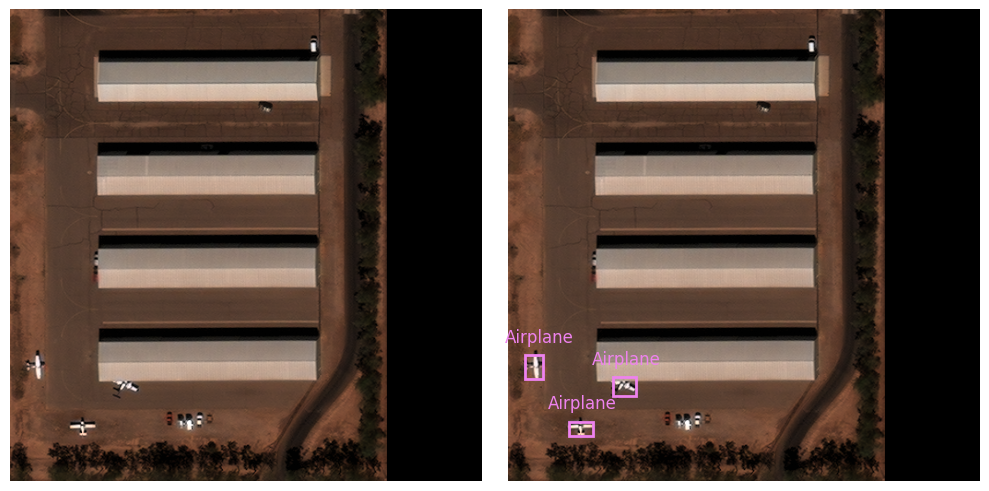

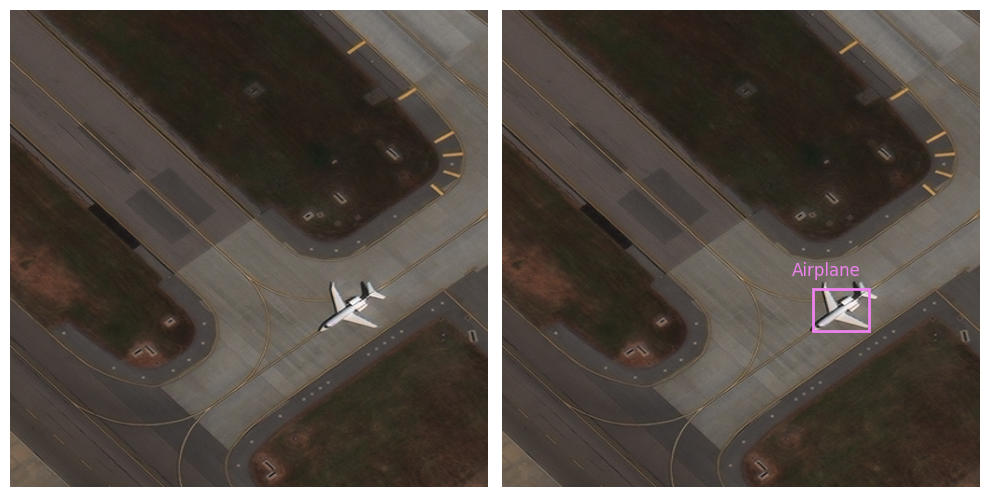

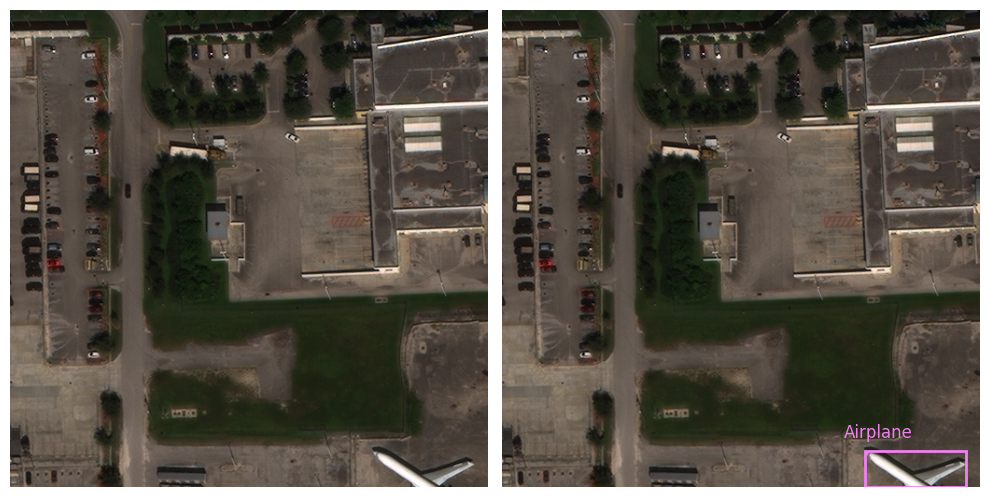

In [32]:
dataset.show_image(50);
dataset.show_image(10);
dataset.show_image(200);

New 60/20/20 splits

In [23]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/RarePlanes/",
    "csv_file": "/home/dragik/data/FAIR_EO/RarePlanes/rare_planes_train.csv"
}
dataset = RarePlanesDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 5115


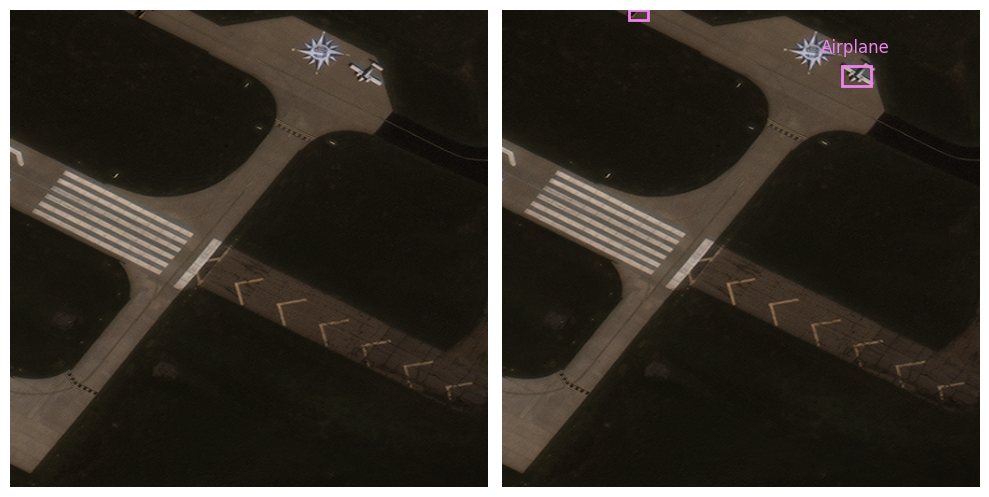

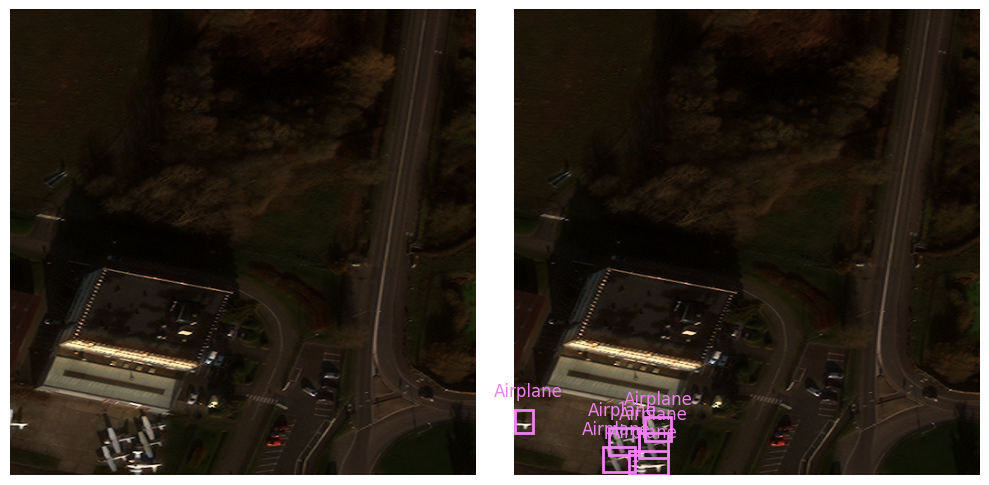

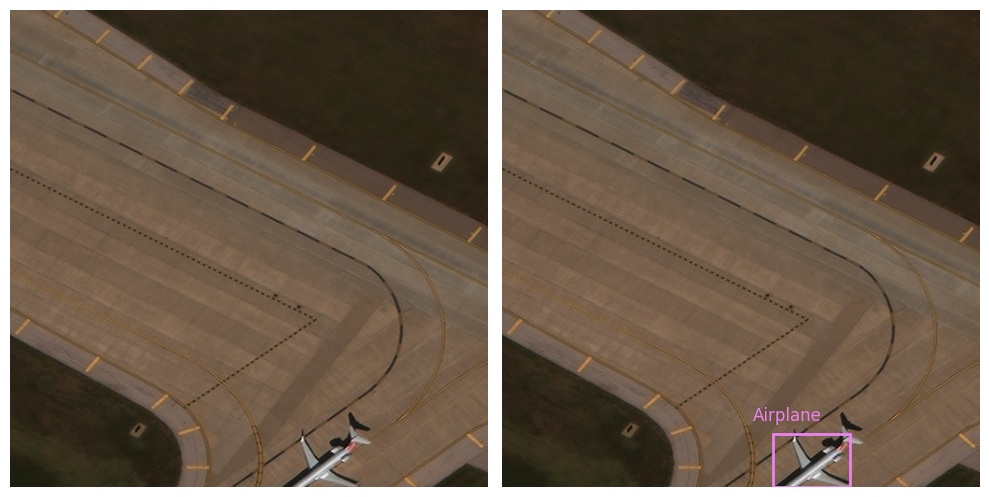

In [24]:
dataset.show_image(50);
dataset.show_image(10);
dataset.show_image(200);

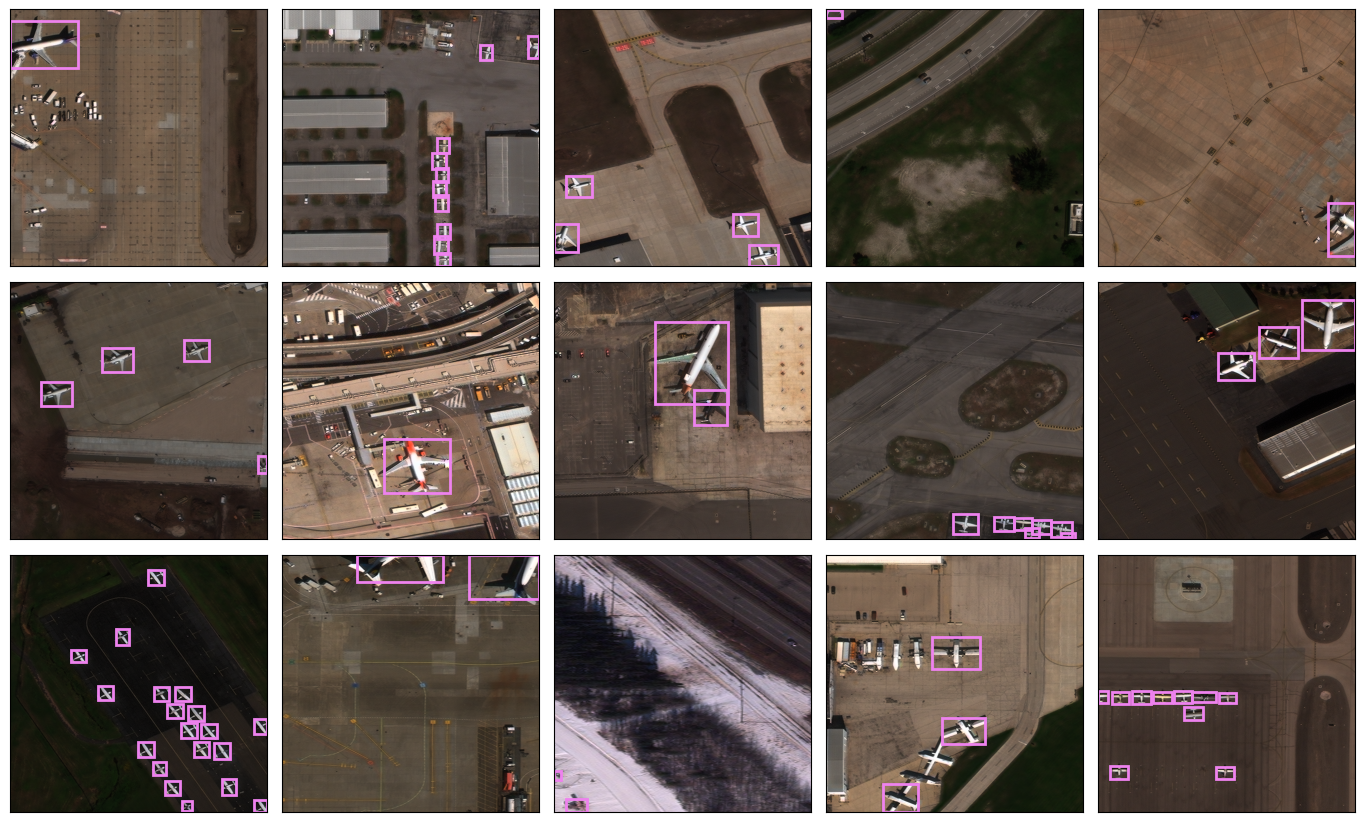

In [45]:
dataset.show_batch(15);

In [46]:
dataset.data_distribution_table()

,Label,Count
0,Airplane,15081


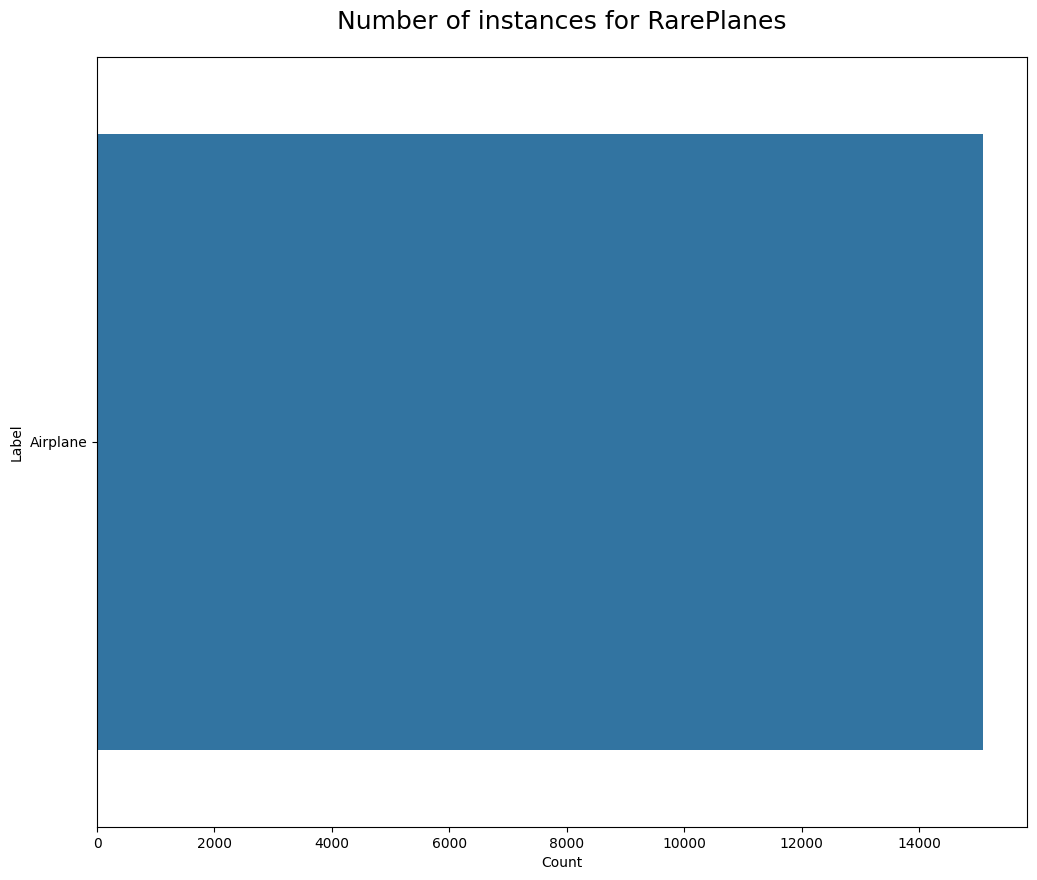

In [47]:
dataset.data_distribution_barchart();

## Load train data

In [33]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/RarePlanes/",
    "csv_file": "/home/dragik/data/FAIR_EO/RarePlanes/rare_planes_train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = RarePlanesDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 5115


## Create the model

In [34]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/RarePlanes/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [35]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2026-01-08 10:03:48,588 INFO Starting training.
training: 100%|██████████| 640/640 [08:10<00:00,  1.31it/s]
2026-01-08 10:11:59,098 INFO epoch: 1, time: 491, loss:  0.17245
testing on train set: 100%|██████████| 640/640 [04:36<00:00,  2.31it/s]
2026-01-08 10:16:47,332 INFO map:0.7820733189582825, map_50:0.9873117804527283, map_75:0.9419544339179993, map_small:0.7448196411132812, map_medium:0.7926697731018066, map_large:0.859138548374176, mar_1:0.28808435797691345, mar_10:0.7464226484298706, mar_100:0.819660484790802, mar_small:0.7896893620491028, mar_medium:0.8295913338661194, mar_large:0.8935917019844055, map_per_class:0.7820733189582825, mar_100_per_class:0.819660484790802, classes:1.0
training: 100%|██████████| 640/640 [06:34<00:00,  1.62it/s]
2026-01-08 10:23:21,583 INFO epoch: 2, time: 394, loss:  0.11285
testing on train set: 100%|██████████| 640/640 [03:45<00:00,  2.84it/s]
2026-01-08 10:27:16,011 INFO map:0.8216114044189453, map_50:0.9885951280593872, map_75:0.9659687876701355,

0.04722347698107959

## Evaluate the model

In [36]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/RarePlanes/",
    "csv_file": "/home/dragik/data/FAIR_EO/RarePlanes/rare_planes_val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = RarePlanesDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 1705


2026-01-08 12:23:27,085 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar
2026-01-08 12:23:28,314 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 214/214 [01:36<00:00,  2.21it/s]


[{'map': 0.8335801362991333,
  'map_50': 0.9790063500404358,
  'map_75': 0.9474344849586487,
  'map_small': 0.8024152517318726,
  'map_medium': 0.8370032906532288,
  'map_large': 0.9080554246902466,
  'mar_1': 0.3014589846134186,
  'mar_10': 0.7908714413642883,
  'mar_100': 0.8625788688659668,
  'mar_small': 0.838492751121521,
  'mar_medium': 0.8661791682243347,
  'mar_large': 0.9306886196136475,
  'map_per_class': 0.8335801362991333,
  'mar_100_per_class': 0.8625788688659668,
  'classes': 1.0}]

## Predictions

2026-01-08 12:25:08,860 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar
2026-01-08 12:25:09,873 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar at epoch 11


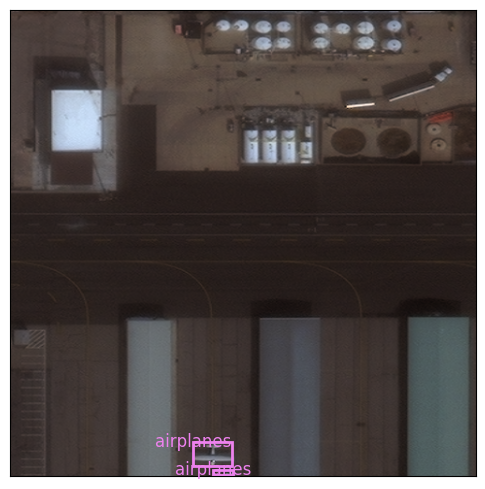

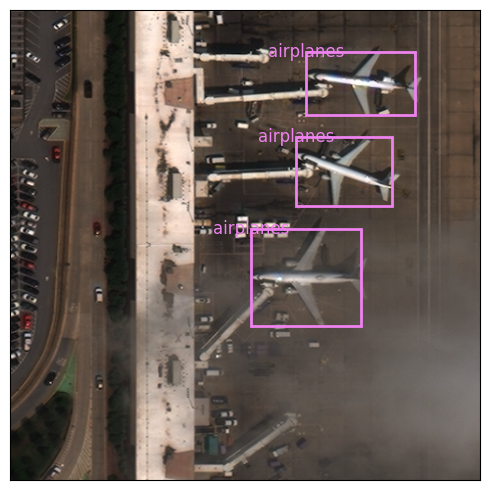

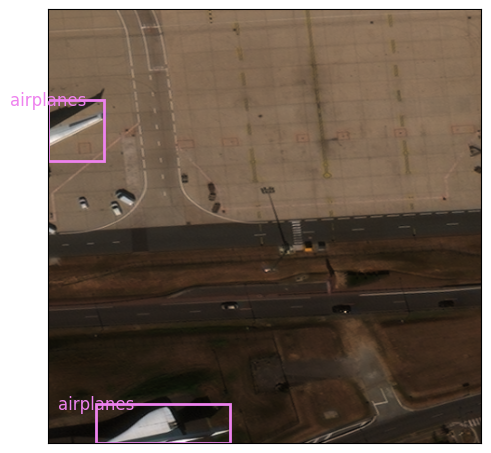

In [37]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar"
labels = ["no-data", "airplanes"]
transform = Resize()
model.load_model(model_path)

image = image_loader("/home/dragik/data/FAIR_EO/RarePlanes/test/PS-RGB_tiled/67_1040010046D15B00_tile_1711.png")
fig = model.detect_objects(image, labels, transform)

image = image_loader("/home/dragik/data/FAIR_EO/RarePlanes/test/PS-RGB_tiled/77_1040010043B0F100_tile_482.png")
fig = model.detect_objects(image, labels, transform)

image = image_loader("/home/dragik/data/FAIR_EO/RarePlanes/test/PS-RGB_tiled/69_104005000CDBE200_tile_2368.png")
fig = model.detect_objects(image, labels, transform)